# Experiment 14: Dropout for widths 256 and 512

Card: [exp14_width_dropout.md](../../experiments/exp14_width_dropout.md)


In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
sys.path.insert(0, "../..")  # the section's src package
from ashrae.config import FOLDS
from ashrae.plots import INK, SURFACE, TEXT, style_axis
from ashrae.tracking import session_runs
from src.data import fold_loaders
from src.networks import MeterMLP
from src.runs import finished_keys, fold_table, session_scores
from src.tracking import Experiment
from src.training import fit_folds

SMOKE = os.environ.get("SMOKE") == "1"
NOTEBOOK = "exp14_width_dropout"
EMB_DIM = 12  # picked in exp03
LR = 1e-2
if SMOKE:
    EXPERIMENT = "ashrae-mlp-width-dropout-smoke"
    TRAIN = True
    SESSION = None
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    EPOCHS = 3
    WIDTHS = [128]  # the only width the exp10 smoke run trained
    DROPOUTS = [0.3]
    # (experiment, session, widths) of the reused runs without dropout; None: the latest session
    REFERENCES = [
        ("ashrae-mlp-width-smoke", None, WIDTHS),
        ("ashrae-mlp-batch-norm-smoke", None, [64]),
    ]
    FIGURE = None
else:
    EXPERIMENT = "ashrae-mlp-width-dropout"
    TRAIN = (
        False  # set False with SESSION to re-read a finished session without training
    )
    SESSION = "2026-10-13 08:00:20"
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    EPOCHS = 40
    WIDTHS = [256, 512]
    DROPOUTS = [0.1, 0.3, 0.5]
    REFERENCES = [
        ("ashrae-mlp-width", "2026-10-12 22:43:11", WIDTHS),  # exp10
        ("ashrae-mlp-batch-norm", "2026-10-12 21:52:51", [64]),  # exp09
    ]
    FIGURE = "../../figures/exp14_width_dropout.png"

experiment = Experiment(EXPERIMENT, NOTEBOOK, SESSION)

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow: sqlite:////Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/mlflow.db, experiment 'ashrae-mlp-width-dropout', session 2026-10-13 08:00:20


## Training


In [2]:
def scores():
    refs = []
    for name, session, widths in REFERENCES:
        ref = session_runs(name, session)
        ref = ref[ref["params.lr"].astype(float) == LR]
        if "width" in ref:  # exp09 trained width 64 only and has no width tag
            ref = ref[ref.width.astype(int).isin(widths)]
        else:
            ref = ref.assign(width=widths[0])
        refs.append(ref.assign(dropout=0.0))
    return session_scores(experiment, {"width": int, "dropout": float}, FOLD_NAMES, refs)

In [3]:
if TRAIN:
    folds, n_buildings, n_features = fold_loaders(FOLD_NAMES, N_TRAIN, N_VAL)
    done = (
        set()
        if SESSION is None
        else finished_keys(scores().query("dropout > 0"), ["width", "dropout", "fold"])
    )

    for width in WIDTHS:
        for p in DROPOUTS:
            fit_folds(
                experiment,
                folds,
                lambda: MeterMLP(
                    n_features,
                    n_buildings,
                    emb_dim=EMB_DIM,
                    batch_norm=True,
                    dropout=p,
                    width=width,
                ),
                f"mlp_4out_emb_bn | width {width} | dropout {p:g}",
                done=done,
                key=(width, p),
                epochs=EPOCHS,
                lr=LR,
                tags={"model": "mlp_4out_emb_bn", "width": str(width), "dropout": f"{p:g}"},
                params={"n_train": N_TRAIN, "n_val": N_VAL, "emb_dim": EMB_DIM, "width": width, "dropout": p},
            )

## Results


In [4]:
results = scores()
print(f"MLflow session {experiment.session}: {len(results)} runs, with the reused ones")

columns = {
    "val_clean": "average, clean rows",
    "best_epoch": "best epoch",
    "train": "training at best epoch",
    "train_last": f"training at epoch {EPOCHS}",
    "epoch_seconds": "seconds per epoch",
    "minutes_to_best": "minutes to best epoch",
}
table, by_setup = fold_table(results, ["width", "dropout"], columns, FOLD_NAMES)
display(table.round(3))

MLflow session 2026-10-13 08:00:20: 36 runs, with the reused ones


RMSLE at the best epoch, all rows unless noted  Jan–Mar  Apr–Jun  Jul–Sep  \
width dropout                                                               
64    0.0                                         1.386    1.195    1.008   
256   0.0                                         1.394    1.200    1.012   
      0.1                                         1.382    1.188    1.007   
      0.3                                         1.381    1.190    1.006   
      0.5                                         1.384    1.192    1.010   
512   0.0                                         1.395    1.196    1.013   
      0.1                                         1.384    1.186    1.008   
      0.3                                         1.378    1.185    1.001   
      0.5                                         1.379    1.190    1.002   

RMSLE at the best epoch, all rows unless noted  Oct–Dec  average  \
width dropout                                                      
64    0.0                                         1.085    1.168   
256   0.0                                         1.090    1.174   
      0.1                                         1.081    1.164   
      0.3                                         1.075    1.163   
      0.5                                         1.084    1.167   
512   0.0                                         1.091    1.174   
      0.1                                         1.083    1.165   
      0.3                                         1.072    1.159   
      0.5                                         1.077    1.162   

RMSLE at the best epoch, all rows unless noted  average, clean rows  \
width dropout                                                         
64    0.0                                                     0.912   
256   0.0                                                     0.911   
      0.1                                                     0.904   
      0.3                                                     0.907   
      0.5                                                     0.915   
512   0.0                                                     0.910   
      0.1                                                     0.910   
      0.3                                                     0.901   
      0.5                                                     0.906   

RMSLE at the best epoch, all rows unless noted  best epoch  \
width dropout                                                
64    0.0                                            35.25   
256   0.0                                            15.75   
      0.1                                            26.00   
      0.3                                            25.00   
      0.5                                            31.25   
512   0.0                                            11.75   
      0.1                                            10.25   
      0.3                                            26.00   
      0.5                                            25.00   

RMSLE at the best epoch, all rows unless noted  training at best epoch  \
width dropout                                                            
64    0.0                                                        0.761   
256   0.0                                                        0.748   
      0.1                                                        0.766   
      0.3                                                        0.807   
      0.5                                                        0.854   
512   0.0                                                        0.740   
      0.1                                                        0.778   
      0.3                                                        0.780   
      0.5                                                        0.817   

RMSLE at the best epoch, all rows unless noted  training at epoch 40  \
width dropout                                      

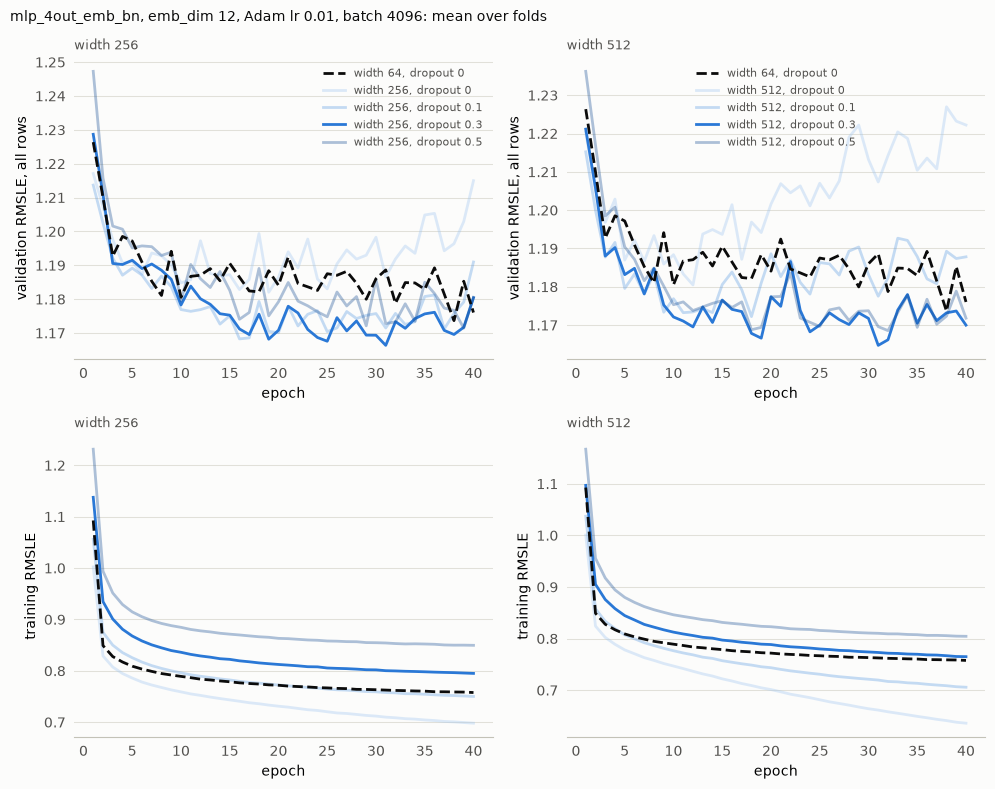

In [5]:
SHADES = [
    "#9ec5f0",
    "#5b9be3",
    "#2a78d6",
    "#174e94",
]  # light to dark: dropout 0 to the largest

fig, axes = plt.subplots(
    2, len(WIDTHS), figsize=(5 * len(WIDTHS), 8), facecolor=SURFACE, squeeze=False
)
reference = results.query("width == 64")
for col, width in enumerate(WIDTHS):
    # width 64 drawn on top; dropouts other than 0.3 faded
    groups = [(64, 0.0, reference, INK, "--", 1.0, 3)] + [
        (width, p, runs, SHADES[i], "-", 1.0 if p == 0.3 else 0.35, 2)
        for i, (p, runs) in enumerate(
            results.query("width == @width").groupby("dropout")
        )
    ]
    for row, (key, label) in enumerate(
        [("val_curve", "validation RMSLE, all rows"), ("train_curve", "training RMSLE")]
    ):
        ax = axes[row, col]
        for w, p, runs, color, ls, alpha, zorder in groups:
            # mean over folds; a diverged run is shorter
            curve = pd.DataFrame(runs[key].tolist()).mean()
            ax.plot(
                np.arange(1, len(curve) + 1),
                curve,
                lw=2,
                color=color,
                ls=ls,
                alpha=alpha,
                zorder=zorder,
                label=f"width {w}, dropout {p:g}",
            )
        ax.set(xlabel="epoch", ylabel=label)
        ax.set_title(f"width {width}", loc="left", color=TEXT, fontsize=9)
        style_axis(ax)
    axes[0, col].legend(frameon=False, fontsize=8, labelcolor=TEXT)
fig.suptitle(
    f"mlp_4out_emb_bn, emb_dim {EMB_DIM}, Adam lr {LR:g}, batch 4096: mean over folds",
    x=0.01,
    ha="left",
    color=INK,
    fontsize=10,
)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in results.query("dropout > 0").run_id:
        experiment.client.log_artifact(run_id, FIGURE)